# Presentation graphs
Plot the client accuracy graphs and tables used in the presentation from the saved CSVs; nothing is trained here.

Prepare the project and its imports; on Google Colab this also downloads the latest committed code.

In [1]:
from pathlib import Path
import importlib.util
import json
import os
import subprocess
import sys

ON_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
REPOSITORY_URL = "https://github.com/s4meer-git/BPDC_FL_Framework.git"

if ON_COLAB:
    PROJECT_ROOT = Path("/content/FLFrameWork")
    if (PROJECT_ROOT / ".git").exists():
        subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", REPOSITORY_URL, str(PROJECT_ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(PROJECT_ROOT / "JPNotebooks" / "requirements.txt")], check=True)
else:
    PROJECT_ROOT = Path.cwd()
    if PROJECT_ROOT.name == "JPNotebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "configuration.py").is_file():
    raise FileNotFoundError("Open this notebook from the project folder, or set PROJECT_ROOT to your checkout.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from support_modules.experiment import diverged_result

print("Project:", PROJECT_ROOT)

Project: /Users/sameer/Desktop/FLFrameWork


Results are read from Results/<dataset>/RUN1, RUN2, RUN3/<selfish|non_selfish>/<method>.csv; on Google Colab they are read from Drive.

In [2]:
RESULTS_ROOT = PROJECT_ROOT / "Results"

if ON_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    RESULTS_ROOT = Path("/content/drive/MyDrive/FLFrameWork/Results")

print("Results:", RESULTS_ROOT)

Results: /Users/sameer/Desktop/FLFrameWork/Results


Choose the dataset and scenario here; the presentation uses MNIST with one selfish client.

In [3]:
DATASET = "mnist"
SCENARIO = "selfish"
RUNS = [("RUN1", 42), ("RUN2", 43), ("RUN3", 44)]
GRAPH_FOLDER = RESULTS_ROOT / DATASET / "ppt_graphs"
GRAPH_FOLDER.mkdir(parents=True, exist_ok=True)


# Fairness methods are drawn with solid lines and the others dotted, as in the report.
NAMES = {"fedavg": "FedAvg", "fairrfl": "FairRFL", "fcfl": "FCFL", "fedcda": "FedCDA", "fedmut": "FedMut"}
COLORS = {"fedavg": "#2a78d6", "fairrfl": "#eb6834", "fcfl": "#1baf7a", "fedcda": "#eda100", "fedmut": "#e87ba4"}
FAIR = {"fairrfl", "fcfl"}
plt.rcParams.update({"font.family": "serif", "font.size": 11, "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False})

print("Graphs:", GRAPH_FOLDER)

Graphs: /Users/sameer/Desktop/FLFrameWork/Results/mnist/ppt_graphs


Run this cell once before plotting the graphs below.

In [4]:
def final_client_accuracy(path):
    data = pd.read_csv(path, usecols=["event", "round_number", "client_id", "data"])
    data = data[data.event == "round_client_accuracy"]
    data = data[data.round_number == data.round_number.max()]
    return pd.Series([100 * json.loads(x)["client_accuracy"] for x in data.data], index=data.client_id.astype(int).values + 1)


# All methods in a RUN use the same selfish client, so it is read from fedavg.csv.
def selfish_ids(folder):
    first = pd.read_csv(folder / "fedavg.csv", nrows=1)
    return json.loads(first.data.iloc[0])["settings"].get("selfish_client_ids", [])


def plot_methods(methods, name):
    fig, axes = plt.subplots(3, 1, figsize=(12, 5.6), sharex=True, sharey=True)
    for ax, (run, seed) in zip(axes, RUNS):
        folder = RESULTS_ROOT / DATASET / run / SCENARIO
        for client_id in selfish_ids(folder):
            ax.axvspan(client_id + 0.55, client_id + 1.45, color="#d9d8d3", alpha=0.7, lw=0)
        stds = []
        for method in methods:
            path = folder / f"{method}.csv"
            if not path.exists() or diverged_result(path):
                stds.append(f"{NAMES[method]}: diverged")
                continue
            accuracy = final_client_accuracy(path)
            ax.plot(accuracy.index, accuracy.values, color=COLORS[method], lw=2 if method in FAIR else 1.6, marker="o", ms=3.5,
                    ls="-" if method in FAIR else ":", label=NAMES[method])
            stds.append(f"{NAMES[method]} std {accuracy.std(ddof=0):.2f} pp")
        ax.set_ylim(25, 102)
        ax.set_yticks([40, 60, 80, 100])
        ax.grid(axis="y", color="#e4e3df", lw=0.8)
        ax.set_axisbelow(True)
        ax.text(0.0, 1.02, f"Seed {seed}", transform=ax.transAxes, fontsize=11, fontweight="bold", color="#0b0b0b")
        ax.text(1.0, 1.02, "   |   ".join(stds), transform=ax.transAxes, fontsize=10, color="#52514e", ha="right")
    axes[-1].set_xticks(range(1, 31))
    axes[-1].tick_params(axis="x", labelsize=9)
    axes[-1].set_xlabel("Client")
    axes[1].set_ylabel("Test accuracy (%)")
    handles, labels = axes[0].get_legend_handles_labels()
    handles.append(plt.Rectangle((0, 0), 1, 1, color="#d9d8d3"))
    labels.append("Selfish client")
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.035), fontsize=11)
    fig.tight_layout(h_pad=1.4)
    png_path = GRAPH_FOLDER / f"clients_{name}.png"
    fig.savefig(png_path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved PNG:", png_path)

FairRFL and FedAvg.

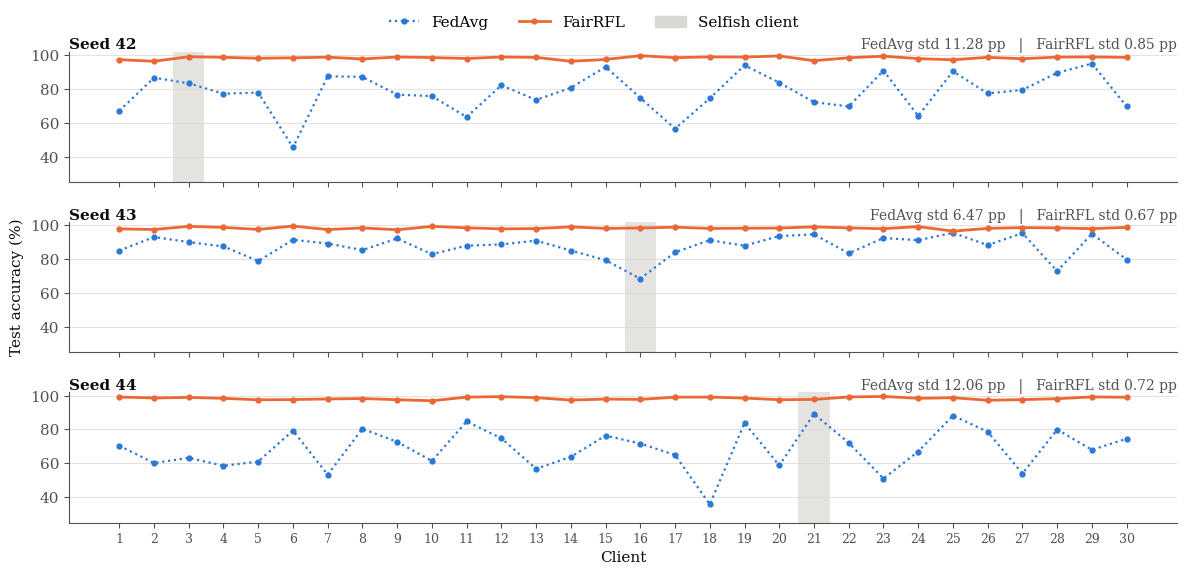

Saved PNG: /Users/sameer/Desktop/FLFrameWork/Results/mnist/ppt_graphs/clients_fair_robust.png


In [5]:
plot_methods(["fedavg", "fairrfl"], "fair_robust")

FCFL and FedAvg.

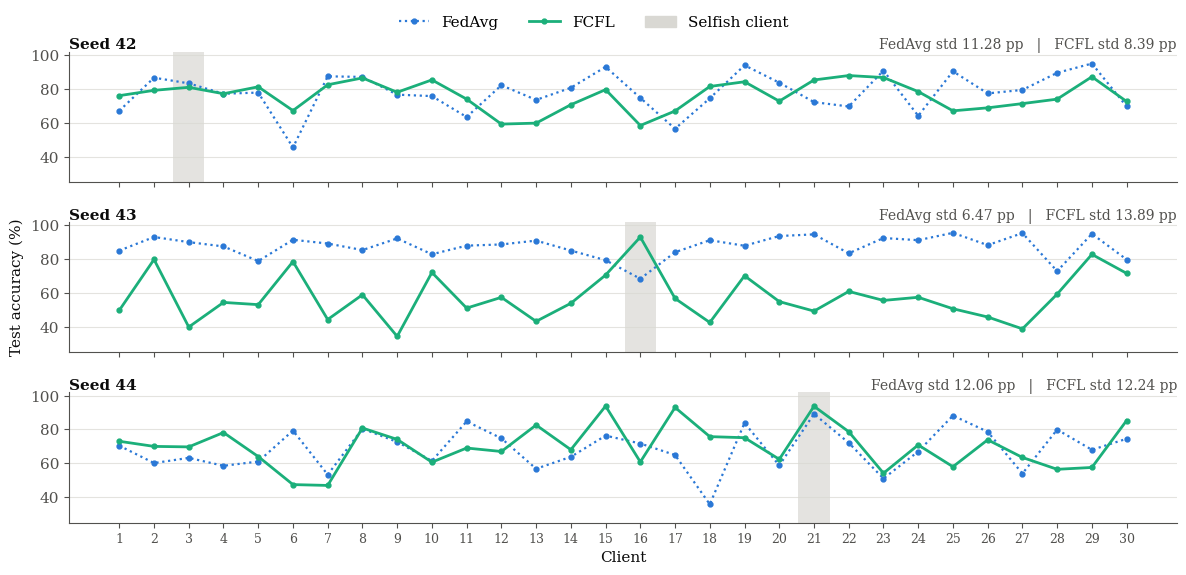

Saved PNG: /Users/sameer/Desktop/FLFrameWork/Results/mnist/ppt_graphs/clients_fair_only.png


In [6]:
plot_methods(["fedavg", "fcfl"], "fair_only")

FedCDA, FedMut and FedAvg; a diverged method is left out of that seed.

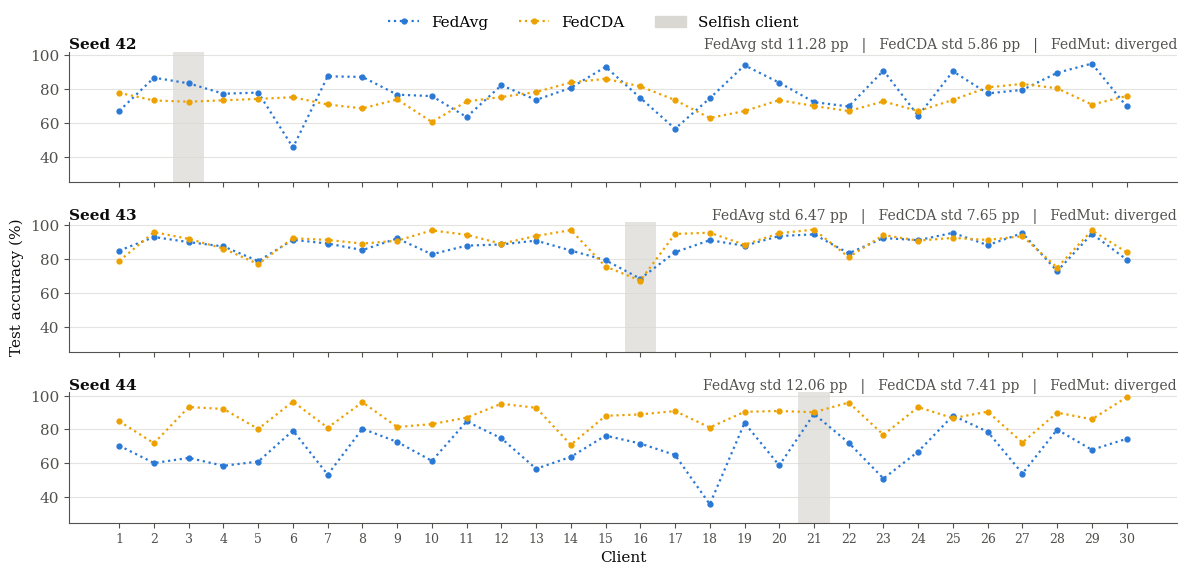

Saved PNG: /Users/sameer/Desktop/FLFrameWork/Results/mnist/ppt_graphs/clients_neither.png


In [7]:
plot_methods(["fedavg", "fedcda", "fedmut"], "neither")

Print Table II for both scenarios; run the Table II cell in setup_remote.ipynb first if a summary is missing.

In [8]:
for scenario in ("non_selfish", "selfish"):
    summary_path = RESULTS_ROOT / DATASET / f"summary_{scenario}.csv"
    if not summary_path.exists():
        print("Missing:", summary_path)
        continue
    print(DATASET, scenario)
    display(pd.read_csv(summary_path, index_col="Method"))

mnist non_selfish


,ACC (%),Mean Client ACC (%),Worst Client ACC (%),Client Std. (%),JFI
Method,,,,,
FedAvg,98.67 ± 0.06,98.65 ± 0.04,97.10 ± 0.72,0.65 ± 0.07,1.0000 ± 0.0000
FairRFL,98.35 ± 0.05,98.34 ± 0.08,96.57 ± 0.35,0.71 ± 0.07,0.9999 ± 0.0000
FedCDA,98.51 ± 0.06,98.48 ± 0.08,96.49 ± 1.49,0.71 ± 0.15,0.9999 ± 0.0000
FCFL,98.52 ± 0.11,98.50 ± 0.21,96.77 ± 1.23,0.71 ± 0.22,0.9999 ± 0.0000


mnist selfish


,ACC (%),Mean Client ACC (%),Worst Client ACC (%),Client Std. (%),JFI
Method,,,,,
FedAvg,77.87 ± 9.92,77.93 ± 9.44,49.91 ± 16.75,9.94 ± 3.03,0.9813 ± 0.0124
FairRFL,98.30 ± 0.04,98.29 ± 0.08,96.57 ± 0.35,0.75 ± 0.09,0.9999 ± 0.0000
FedCDA,83.13 ± 8.57,83.44 ± 8.45,66.27 ± 5.34,6.97 ± 0.97,0.9931 ± 0.0005
FCFL,67.02 ± 10.44,67.97 ± 9.30,46.60 ± 11.97,11.50 ± 2.82,0.9679 ± 0.0214
